# Is one repair pass enough?

`ReorderingInsertionPolicy` runs **one** relocate-repair sweep per planning
call. Each accepted relocation changes the schedule the next candidate is
judged against, so a single sweep already compounds — but there is no reason
it should exhaust the neighbourhood. A move that was not an improvement early
in the sweep may become one after three other requests have shifted around it.

We have never checked. `n_passes` has been `1` since L1 was written, and every
measured L1 result — mean ride −12%, max ride −11%, wait −2%, coverage
+0.8 pp — is a one-pass result.

This notebook asks whether that leaves anything on the table, using the
`n_passes=None` mode that sweeps until a pass accepts nothing.

## Why this is the right question to ask now

It is the test that tells us whether **L1 is finished**.

A converged schedule is a local optimum for the relocate operators: no single
request can be moved anywhere cheaper. Reaching it and finding no further gain
means the remaining headroom is not reachable by moving one request at a time,
and the only way up is a move that displaces several at once — which is L2,
a much larger piece of work with its own randomness and its own tuning
surface.

So both outcomes are useful, and that is deliberate:

- **Convergence buys little** → L1 is done. We can say so with evidence rather
  than for lack of time, and the case for L2 rests on a measured ceiling.
- **Convergence buys a lot** → a free improvement for a three-line change, and
  the one-pass figures in the docs understate what reordering is worth.

## The questions, and what would settle them

### Q1 — does converging improve the KPIs?

Paired per-trial differences against the one-pass column.

- **No significant change on any metric** → one pass is the whole of L1. This
  is the outcome the acceptance rule makes likely: a sweep only takes strict
  improvements, so the cheap moves are taken first and later passes are left
  picking over what remains.
- **Significant improvement** → one pass was leaving gains unclaimed, and the
  default should change.
- **Significant *degradation*** → would indicate a bug, not a result. Repair
  only accepts moves that lower the modelled cost, so more repair cannot make
  the model worse. If measured KPIs fall while modelled cost falls too, the
  cost function is mis-specified — which would matter far more than this
  experiment.

### Q2 — how many passes does convergence actually take?

`repair_passes / repair_calls`. The floor is **1**, not 2: a call whose first
sweep accepts nothing has already converged and stops there. Only a call that
relocates something pays for a second sweep to confirm there is nothing left.

That makes this number a mixture of two populations, and worth reading as
such:

- **≈ 1** → most planning calls relocate nothing at all, and repair is idling.
- **≈ 2** → calls that do relocate almost always finish in one sweep, and
  `n_passes=2` would be indistinguishable from converging.
- **Materially above 2** → sweeps genuinely keep finding moves, and the
  interesting question becomes where the gain flattens.

A one-trial probe put this at **1.26**, which — if it holds — means roughly a
quarter of repair calls accept anything at all, and the rest converge
immediately. Treat that as a hint about what to expect, not a result.

### Q3 — what does it cost?

Wall-clock per column, and cost per second of ride time saved. L1 already
prices at 3.4× L0 with 97.5% of relocation attempts wasted. If convergence
doubles the repair bill for a fraction of a percent of ride time, that settles
the tuning question regardless of statistical significance.

The `n_passes=2` column exists to price the middle option: if convergence
turns out to need many passes but most of the gain lands early, a fixed count
is the cheaper way to bound planning time.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics
import time
from collections import defaultdict
from typing import Callable

import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import BusState, DispatchPolicy
from src.algorithm.ReorderingInsertionPolicy import ReorderingInsertionPolicy
from src.algorithm.RequestPool import Request
from src.algorithm.Schedule import Schedule
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    TrialResult,
    run_trial,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


class _RejectionCounting:
    """
    Mixin recording how often the policy refused to schedule a request.

    Carried over unchanged from ``reordering-window-sweep.ipynb``. It counts
    per call site rather than in total because L1 reaches ``_best_insertion``
    from three places — first-pass insertion, relocation, and retry — and
    pooling them compares L0's first-pass attempts against a denominator four
    to five times larger for L1.

    Counts live on the instance and are read back through ``stats()``. One
    policy is built per trial, so run totals are a sum over instances.
    """

    def __init__(self, *args: object, **kwargs: object) -> None:
        """Forward every argument to the policy being wrapped."""
        super().__init__(*args, **kwargs)
        self._counts: dict[str, float] = {
            "plan_calls": 0.0,
            "offered": 0.0,
            "left_unscheduled": 0.0,
            "insertion_attempts": 0.0,
            "rejections": 0.0,
            "relocation_attempts": 0.0,
        }
        self._context = "insertion"

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """Plan normally, then record who was left waiting."""
        self._context = "insertion"
        offered = {request.id for request in state.pending_requests}
        route = super().plan(state, n_stops)
        self._counts["plan_calls"] += 1
        self._counts["offered"] += len(offered)
        self._counts["left_unscheduled"] += len(
            offered - self.schedule.owners()
        )
        return route

    def _best_insertion(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Insert normally, then tally the outcome against its call site."""
        result = super()._best_insertion(schedule, request, state)
        if self._context == "relocation":
            self._counts["relocation_attempts"] += 1
        else:
            self._counts["insertion_attempts"] += 1
            if result is None:
                self._counts["rejections"] += 1
        return result

    def _relocate_pair(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Mark the re-placement so it is not counted as a first insertion."""
        self._context = "relocation"
        try:
            return super()._relocate_pair(schedule, request, state)
        finally:
            self._context = "insertion"

    def stats(self) -> dict[str, float]:
        """
        Merge these counters with any the wrapped policy reports.
        :return: Counter name to value.
        """
        merged = dict(self._counts)
        inherited = getattr(super(), "stats", None)
        if inherited is not None:
            merged.update(inherited())
        return merged


class CountingL0(_RejectionCounting, WindowInsertionPolicy):
    """Insert-only baseline, instrumented."""


class CountingL1(_RejectionCounting, ReorderingInsertionPolicy):
    """Relocate-repair policy, instrumented."""


# Every policy built during the run, per column. Cleared by the run cell.
INSTANCES: dict[str, list[object]] = defaultdict(list)


def make_factory(
    label: str, policy_class: type, window: float, **policy_kwargs: object,
) -> Callable[[TransitGraph], DispatchPolicy]:
    """
    Build a policy factory that registers what it builds.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param label: Column label the instances are filed under.
    :param policy_class: Policy to construct.
    :param window: Service window in seconds.
    :param policy_kwargs: Extra keyword arguments for the policy, which is
        how the n_passes setting reaches each column.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> DispatchPolicy:
        policy = policy_class(graph, max_wait_s=window, **policy_kwargs)
        INSTANCES[label].append(policy)
        return policy
    return factory

## 1. Configuration

### One window, not a sweep

`reordering-window-sweep.ipynb` covers the window axis. This notebook holds
the window fixed at **750 s** — the strongest operating point in the 800-trial
baseline, and the one the project would ship — and varies only the pass count.
Mixing both axes would quadruple the runtime to answer a question that does
not need it.

If the window sweep moves the recommended operating point, change `WINDOW`
below and re-run; nothing else in the notebook depends on the value.

### Choosing `N_TRIALS`

The awkward part of this experiment is that **its most likely result is a
null**, and a null needs a tight interval to mean anything. "No significant
difference" with a ±30 s half-width on mean ride would be worthless, because
it would be consistent with a 25 s improvement.

From the L1 ablation's observed spread, the paired half-width on mean ride was
±6.9 s at 200 trials, so:

| trials | half-width on mean ride |
|---|---|
| 200 | ±6.9 s |
| 300 | ±5.6 s |
| 400 | ±4.9 s |

At **300** we can state a null as "any gain from converging is smaller than
about 6 s of mean ride, against the 63.7 s that L1 itself buys" — an order of
magnitude below the effect it would be adding to, which is a strong enough
statement to close the question. Going to 400 tightens that to 5 s for a third
more runtime, which does not change the conclusion either way.

### Runtime

Measured, one trial per column:

| L0 | L1 n=1 | L1 n=2 | L1 converge |
|---|---|---|---|
| 1.7 s | 5.9 s | 10.4 s | 7.4 s |

25.2 s per trial, so **about 2.1 hours** at 300 trials. The probe cell below
re-measures on the machine actually running it.

Note that **converging is cheaper than a fixed two passes** — 7.4 s against
10.4 s. That is the early stop paying for itself: a fixed count re-sweeps
every schedule whether or not the first pass found anything, while converging
abandons the ones that are already settled. It also means the middle option
`n=2` is dominated on this map: it costs more than converging *and* does
strictly less work where it matters.

### The awkward possibility

If Q2 really lands near 1.26, then roughly three quarters of repair calls
accept nothing on their first sweep, and the KPI difference between `n=1` and
converging is being generated by the remaining quarter. Those are presumably
the calls with the longest schedules — the ones where reordering has the most
to work with.

So a null on Q1 would need reading carefully. It would not mean "extra passes
never help"; it would mean "extra passes help too rarely to move a mean". The
cost table in section 7 is what distinguishes those, and the acceptance rate
in section 6 is what says whether later passes are finding real moves or
scraping.

In [2]:
N_TRIALS = 300
BASE_SEED = 0

# The recommended operating point from the 800-trial baseline: best served
# fraction, mean wait, P90 wait and mean ride among the swept windows.
WINDOW = 750.0

# run_trial kwargs matching every previous campus experiment. NOTE: max_wait_s
# here is the *backend's abandonment threshold*, a different quantity from the
# policy's service window above.
LOAD = dict(
    max_requests=200, capacity=40, max_wait_s=900.0, commitment=0,
)

# (label, policy class, policy kwargs). retry_rejected is passed explicitly
# even though False is now the default, because it is load-bearing: leaving it
# on would add a second mechanism to every L1 column and confound the answer.
LEVELS: list[tuple[str, type, dict]] = [
    ("L0", CountingL0, {}),
    ("L1 n=1", CountingL1, dict(n_passes=1, retry_rejected=False)),
    ("L1 n=2", CountingL1, dict(n_passes=2, retry_rejected=False)),
    ("L1 converge", CountingL1, dict(n_passes=None, retry_rejected=False)),
]

POLICIES: list[tuple[str, Callable[[TransitGraph], DispatchPolicy]]] = [
    (label, make_factory(label, policy_class, WINDOW, **policy_kwargs))
    for label, policy_class, policy_kwargs in LEVELS
]
COLUMNS = [label for label, _ in POLICIES]
REFERENCE = "L1 n=1"  # every delta below is measured against this column

print(f"{len(COLUMNS)} columns at W{WINDOW:.0f}: {', '.join(COLUMNS)}")

4 columns at W750: L0, L1 n=1, L1 n=2, L1 converge


## 2. Shared map

Identical to every previous sweep — same `MAP_SEED`, same campus
configuration — so the `L0` and `L1 n=1` columns are directly comparable to
`baseline-c0.ipynb` and `reordering-l1-ablation.ipynb`.

In [3]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


## 3. Cost check

One trial per column before committing to three hundred. This also gives the
first read on Q3: if `L1 converge` costs barely more than `L1 n=1`, then
convergence is nearly free and Q2 will come back at ≈2 passes.

In [4]:
probe_costs: dict[str, float] = {}
for label, factory in POLICIES:
    start = time.perf_counter()
    run_trial(
        policy_factory=factory, graph=graph, seed=BASE_SEED,
        silent=True, **LOAD,
    )
    probe_costs[label] = time.perf_counter() - start

# The probe policies carry counters from a single trial; keep them for the
# pass-count preview, then let the run cell clear them.
probe_passes = {
    label: sum(
        policy.stats().get("repair_passes", 0.0)
        for policy in INSTANCES[label]
    ) / max(
        sum(
            policy.stats().get("repair_calls", 0.0)
            for policy in INSTANCES[label]
        ), 1.0,
    )
    for label in COLUMNS
}

lines = ["| Column | seconds | vs L0 | passes / call |",
         "| --- | --- | --- | --- |"]
for label in COLUMNS:
    lines.append(
        f"| {label} | {probe_costs[label]:.1f} s "
        f"| {probe_costs[label] / probe_costs['L0']:.1f}x "
        f"| {probe_passes[label]:.2f} |"
    )
projected_s = N_TRIALS * sum(probe_costs.values())
lines.append("")
lines.append(
    f"Projected total ({N_TRIALS} trials x {len(COLUMNS)} columns): "
    f"**{projected_s / 3600:.1f} hours**"
)
display(Markdown("\n".join(lines)))

| Column | seconds | vs L0 | passes / call |
| --- | --- | --- | --- |
| L0 | 1.0 s | 1.0x | 0.00 |
| L1 n=1 | 3.4 s | 3.5x | 1.00 |
| L1 n=2 | 6.2 s | 6.4x | 2.00 |
| L1 converge | 4.6 s | 4.7x | 1.26 |

Projected total (300 trials x 4 columns): **1.3 hours**

## 4. The run

One call, so every column shares `base_seed` and trial *i* faces the same
demand sequence throughout — which is what makes the paired differences below
valid.

In [5]:
INSTANCES.clear()  # re-running this cell replaces the tallies

summary = summarize_comparison(
    policies=POLICIES,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **LOAD,
)

L0         :   0%|          | 0/300 [00:00<?, ?it/s]

L1 n=1     :   0%|          | 0/300 [00:00<?, ?it/s]

L1 n=2     :   0%|          | 0/300 [00:00<?, ?it/s]

L1 converge:   0%|          | 0/300 [00:00<?, ?it/s]

## 5. Does converging change the KPIs? (Q1)

Paired per-trial differences against `L1 n=1`. Positive is better for served
fraction; negative is better for every timing row. Bold marks a significant
improvement.

The `L0` row is the regression check, not a result: it should reproduce the
known W750 baseline (91.1% served, 596 s mean ride at 800 trials). A
disagreement there matters more than anything else on the page.

In [6]:
def paired_delta(
    baseline: list[TrialResult],
    treatment: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> tuple[float, float, float]:
    """
    Mean per-trial difference (treatment - baseline) with a CI and a p-value.

    Trials are paired by index, which is meaningful because every column ran
    in one summarize_comparison call, so trial i faced the same demand
    sequence throughout.
    :param baseline: Per-trial results for the reference column.
    :param treatment: Per-trial results for the column being tested.
    :param extract: Maps a TrialResult to the scalar being compared, or None
        when that trial does not define it.
    :return: (mean difference, 95% CI half-width, two-sided paired p-value).
        The last two are NaN with fewer than two usable pairs.
    """
    pairs = [
        (before, after)
        for base_trial, treat_trial in zip(baseline, treatment)
        if (before := extract(base_trial)) is not None
        and (after := extract(treat_trial)) is not None
    ]
    if not pairs:
        return float("nan"), float("nan"), float("nan")

    differences = [after - before for before, after in pairs]
    mean_difference = statistics.fmean(differences)
    if len(differences) < 2:
        return mean_difference, float("nan"), float("nan")

    half_width = (
        stats.t.ppf(0.975, len(differences) - 1)
        * statistics.stdev(differences)
        / len(differences) ** 0.5
    )
    p_value = float(stats.ttest_rel(
        [after for _, after in pairs],
        [before for before, _ in pairs],
    ).pvalue)
    return mean_difference, half_width, p_value


def served_pp(trial: TrialResult) -> float | None:
    """
    Served fraction as percentage points, or None when undefined.
    :param trial: One trial's results.
    :return: Served fraction x 100, or None.
    """
    if trial.kpi.served_fraction is None:
        return None
    return 100.0 * trial.kpi.served_fraction


def max_ride(trial: TrialResult) -> float | None:
    """
    Longest ride in one trial, or None when nobody was carried.
    :param trial: One trial's results.
    :return: Maximum ride time in seconds, or None.
    """
    return max(trial.ride_times) if trial.ride_times else None


def mean_of(
    trials: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> float:
    """
    Mean of one metric across trials, ignoring trials that lack it.
    :param trials: Per-trial results.
    :param extract: Maps a TrialResult to the scalar.
    :return: The mean, or NaN when no trial defined it.
    """
    values = [v for t in trials if (v := extract(t)) is not None]
    return statistics.fmean(values) if values else float("nan")


# (display name, extractor, direction that counts as an improvement)
_MetricSpec = tuple[str, Callable[[TrialResult], float | None], str]

METRICS: list[_MetricSpec] = [
    ("Served (pp)", served_pp, "higher"),
    ("Mean wait (s)", lambda r: r.kpi.mean_wait_time, "lower"),
    ("Mean ride (s)", lambda r: r.kpi.mean_ride_time, "lower"),
    ("Max ride (s)", max_ride, "lower"),
]

for metric_name, extract, better in METRICS:
    lines = [
        f"**{metric_name}** — deltas measured against `{REFERENCE}`", "",
        "| Column | mean | delta vs reference | p |",
        "| --- | --- | --- | --- |",
    ]
    reference_trials = summary.results[REFERENCE]
    for label in COLUMNS:
        trials = summary.results[label]
        delta, half_width, p_value = paired_delta(
            reference_trials, trials, extract
        )
        improved = delta > 0 if better == "higher" else delta < 0
        mark = "**" if p_value < 0.05 and improved else ""
        cell = (
            "reference" if label == REFERENCE
            else f"{mark}{delta:+.1f} ± {half_width:.1f}{mark}"
        )
        p_cell = "—" if label == REFERENCE else f"{p_value:.4f}"
        lines.append(
            f"| {label} | {mean_of(trials, extract):.1f} | {cell} "
            f"| {p_cell} |"
        )
    display(Markdown("\n".join(lines)))

**Served (pp)** — deltas measured against `L1 n=1`

| Column | mean | delta vs reference | p |
| --- | --- | --- | --- |
| L0 | 91.0 | -0.8 ± 0.2 | 0.0000 |
| L1 n=1 | 91.8 | reference | — |
| L1 n=2 | 91.8 | -0.0 ± 0.1 | 0.9439 |
| L1 converge | 91.8 | +0.0 ± 0.1 | 0.9085 |

**Mean wait (s)** — deltas measured against `L1 n=1`

| Column | mean | delta vs reference | p |
| --- | --- | --- | --- |
| L0 | 424.9 | +2.9 ± 2.3 | 0.0108 |
| L1 n=1 | 421.9 | reference | — |
| L1 n=2 | 421.7 | -0.3 ± 1.1 | 0.6430 |
| L1 converge | 421.6 | -0.3 ± 1.2 | 0.5724 |

**Mean ride (s)** — deltas measured against `L1 n=1`

| Column | mean | delta vs reference | p |
| --- | --- | --- | --- |
| L0 | 596.8 | +92.4 ± 7.4 | 0.0000 |
| L1 n=1 | 504.4 | reference | — |
| L1 n=2 | 503.8 | -0.7 ± 2.8 | 0.6234 |
| L1 converge | 503.9 | -0.6 ± 2.7 | 0.6867 |

**Max ride (s)** — deltas measured against `L1 n=1`

| Column | mean | delta vs reference | p |
| --- | --- | --- | --- |
| L0 | 3119.2 | +277.1 ± 106.1 | 0.0000 |
| L1 n=1 | 2842.1 | reference | — |
| L1 n=2 | 2805.2 | -36.9 ± 54.7 | 0.1854 |
| L1 converge | 2819.7 | -22.4 ± 57.1 | 0.4411 |

## 6. How many passes does convergence take? (Q2)

The direct readout. `repair_passes / repair_calls` is the mean number of
sweeps a repair ran. **The floor is 1**: a call whose first sweep accepts
nothing has converged already and stops there, and only a call that relocated
something pays for a confirming sweep. So this figure is really reporting what
fraction of calls found anything to do.

`acceptance rate` is the share of relocation attempts that produced an
improvement. If later passes are doing real work it should stay roughly
constant across columns; if they are picking over exhausted ground it will
fall as passes are added.

In [7]:
def totals(label: str) -> dict[str, float]:
    """
    Sum the counters of every policy built for one column.
    :param label: Column label.
    :return: Counter name to run total, empty if the column never ran.
    """
    merged: dict[str, float] = defaultdict(float)
    for policy in INSTANCES[label]:
        for key, value in policy.stats().items():
            merged[key] += value
    return dict(merged)


def rate(numerator: float, denominator: float) -> float:
    """
    Percentage ratio degrading to NaN rather than raising.
    :param numerator: Count of events.
    :param denominator: Count of opportunities.
    :return: Percentage, or NaN when denominator is zero.
    """
    if not denominator:
        return float("nan")
    return 100.0 * numerator / denominator


TOTALS = {label: totals(label) for label in COLUMNS}

lines = [
    "| Column | passes / call | relocations tried | accepted "
    "| acceptance rate | cost improvement |",
    "| --- | --- | --- | --- | --- | --- |",
]
for label in COLUMNS:
    counters = TOTALS[label]
    calls = counters.get("repair_calls", 0.0)
    passes = counters.get("repair_passes", 0.0)
    tried = (
        counters.get("pair_attempts", 0.0)
        + counters.get("dropoff_attempts", 0.0)
    )
    accepted = (
        counters.get("pair_accepted", 0.0)
        + counters.get("dropoff_accepted", 0.0)
    )
    per_call = passes / calls if calls else float("nan")
    lines.append(
        f"| {label} | {per_call:.2f} | {tried:,.0f} | {accepted:,.0f} "
        f"| {rate(accepted, tried):.1f} % "
        f"| {counters.get('cost_improvement', 0.0):,.0f} s |"
    )
display(Markdown("\n".join(lines)))
display(Markdown(
    "*`cost improvement` is the policy's own modelled saving, summed over "
    "every accepted relocation. It is an internal quantity, not a KPI — its "
    "value is that it can be checked against the measured ride-time saving, "
    "which is what validated the cost function in the L1 ablation.*"
))

| Column | passes / call | relocations tried | accepted | acceptance rate | cost improvement |
| --- | --- | --- | --- | --- | --- |
| L0 | nan | 0 | 0 | nan % | 0 s |
| L1 n=1 | 1.00 | 788,611 | 25,029 | 3.2 % | 6,622,321 s |
| L1 n=2 | 2.00 | 1,572,866 | 25,702 | 1.6 % | 6,574,610 s |
| L1 converge | 1.26 | 1,009,810 | 25,785 | 2.6 % | 6,563,180 s |

*`cost improvement` is the policy's own modelled saving, summed over every accepted relocation. It is an internal quantity, not a KPI — its value is that it can be checked against the measured ride-time saving, which is what validated the cost function in the L1 ablation.*

## 7. What does the extra work buy? (Q3)

Runtime against gain. The question a tuning decision actually turns on is not
whether convergence helps but whether it helps *enough per second spent*.

`L1 n=1` is the reference at zero extra cost, so its row is blank by
construction.

| Column | probe seconds | extra cost | mean ride saved | seconds of ride per extra second spent |
| --- | --- | --- | --- | --- |
| L1 n=1 | 3.4 s | +0.0 s | -0.0 s | reference |
| L1 n=2 | 6.2 s | +2.8 s | +0.7 s | 0.2 |
| L1 converge | 4.6 s | +1.1 s | +0.6 s | 0.5 |

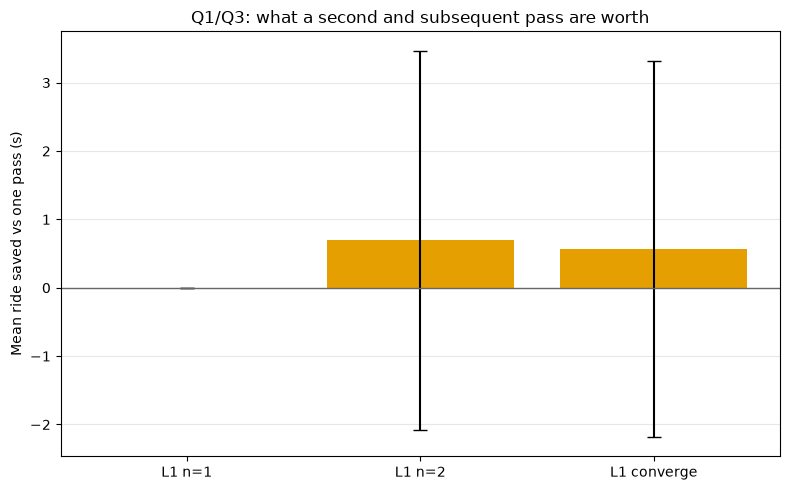

In [8]:
# Colourblind-safe pair in fixed order, validated for CVD separation.
COST_COLOUR = "#1f77b4"
GAIN_COLOUR = "#e69f00"

mean_ride = lambda trial: trial.kpi.mean_ride_time  # noqa: E731
reference_trials = summary.results[REFERENCE]
reference_cost = probe_costs[REFERENCE]

lines = [
    "| Column | probe seconds | extra cost | mean ride saved "
    "| seconds of ride per extra second spent |",
    "| --- | --- | --- | --- | --- |",
]
for label in COLUMNS:
    if label == "L0":
        continue
    delta, _, _ = paired_delta(
        reference_trials, summary.results[label], mean_ride
    )
    extra_cost = probe_costs[label] - reference_cost
    if label == REFERENCE:
        efficiency = "reference"
    elif extra_cost <= 0:
        efficiency = "free"
    else:
        # Ride seconds saved per passenger, per extra second of planning.
        efficiency = f"{-delta / extra_cost:.1f}"
    lines.append(
        f"| {label} | {probe_costs[label]:.1f} s | {extra_cost:+.1f} s "
        f"| {-delta:+.1f} s | {efficiency} |"
    )
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(8, 5))
labels = [label for label in COLUMNS if label != "L0"]
savings = [
    -paired_delta(
        reference_trials, summary.results[label], mean_ride
    )[0]
    for label in labels
]
errors = [
    paired_delta(
        reference_trials, summary.results[label], mean_ride
    )[1]
    for label in labels
]
ax.bar(labels, savings, yerr=errors, capsize=5, color=GAIN_COLOUR)
ax.axhline(0, color="0.4", linewidth=1)
ax.set_ylabel("Mean ride saved vs one pass (s)")
ax.set_title("Q1/Q3: what a second and subsequent pass are worth")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## What to look for

**Regression check first.** `L0` should reproduce W750 from
`baseline-c0.ipynb` (91.1% served, 596 s mean ride) and `L1 n=1` should
reproduce the L1 ablation's improvement over it. That run used 800 trials to
this one's 300, so expect wider intervals rather than different means. If the
means disagree, stop and find out why before reading anything else — the most
likely cause would be the `n_passes` change altering the one-pass path, which
it must not.

**Q2 before Q1.** The pass count bounds what Q1's answer can be. Remember the
floor is 1, so a figure near 1.3 means most calls never relocate anything and
the whole effect is carried by a minority of calls. If it sits at ≈2.0 then
calls that do relocate finish in one sweep, and any difference between
`L1 n=1` and `L1 converge` is noise by construction — there is no mechanism
for it. Read Q1 in that light rather than hunting for significance.

**Q1 — the deltas.**

- *No significant change anywhere* → **L1 is finished.** One pass is all the
  relocate operators have to give on this map, and the ceiling is a property
  of the neighbourhood, not of the budget. This closes L1 with evidence and
  makes L2 the only remaining direction — which is exactly the conclusion
  worth having before setting routing aside for CARLA.
- *Significant improvement, small* → change the default to `None` if the cost
  table justifies it, and re-baseline. Note the size against L1's own 63.7 s:
  a 3 s gain is real but not worth re-running the whole campaign for.
- *Significant improvement, large* → the docs understate reordering, and the
  window sweep's L1 columns are measuring a handicapped policy. That would
  argue for re-running it with the new default before drawing conclusions
  from it.
- *Significant degradation* → treat as a bug report, not a result. More repair
  cannot raise the modelled cost, so a KPI that worsens while
  `cost_improvement` grows means the cost function does not track what we
  actually care about. That would undercut the L1 ablation's cost-validation
  finding and would need chasing before anything else proceeds.

**Q3 — the cost.** If convergence is within a few percent of one pass on
runtime, it is free and the default can change on the strength of any
improvement at all. If it is materially dearer, weigh it against the fact that
97.5% of relocation attempts already fail: spending more on a search that
misses 39 times in 40 is the least attractive place to add compute, and
filtering candidates would be the better investment.

**A note on what this cannot tell us.** All of it is measured at W750 on one
map. If convergence pays anywhere it should pay most where the order is worst,
which the window sweep identifies as W450. A null here is a null *at the
operating point* — strong enough to settle the default, not strong enough to
say the relocate neighbourhood is exhausted everywhere.